# Персональные top-10 рекомендации Домашнее задание 1

**Ибрагимова Ксения Рамилевна**

В этой работе я сравниваю пять самостоятельно реализованных рекомендательных моделей:
ItemKNN, Explicit ALS, EASE, FM с метапризнаками и ALS с разработанным целевым сигналом.
Я использую Amazon Reviews 2018, категорию Video Games, и оцениваю рекомендации
ранее неизвестных пользователю товаров по будущим оценкам 4–5.

## 1. Загрузка и описание данных


In [40]:
from pathlib import Path
import gc
import gzip
import hashlib
import html
import json
import random
import re
import sys
import time
import numpy as np
import pandas as pd
from scipy import sparse
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown
from tqdm.auto import tqdm
PROJECT_ROOT = Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from models import (ItemKNN, ExplicitALS, EASE, FactorizationMachine, CustomTargetALS, target_matrix)
SEED, K, PRIMARY_METRIC = 42, 10, 'NDCG@10'
random.seed(SEED)
np.random.seed(SEED)
CONFIG = dict(max_items=4000, max_users=20000, min_user=5, min_item=5, max_eval_users=2000)
DATA_DIR = PROJECT_ROOT / 'data'
MAIN_MODELS = ['ItemKNN', 'ALS', 'EASE', 'FM + metadata', 'Custom ALS']

### 1.2. Данные

Данные из **Amazon Review Data (2018), Video Games, 5-core**. Источник https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/).
Там 497 577 отзывов в этой 5-core выборке и отдельный
файл метаданных товаров. 5-core означает, что каждый пользователь и товар исходной выборки имеют не менее пяти отзывов.

| В источнике | Наше обозначение  | Смысл |
|---|---|---|
| reviewerID | user_id | идентификатор пользователя |
| asin | item_id | идентификатор товара |
| overall | rating | явная оценка от 1 до 5 |
| unixReviewTime | timestamp | время отзыва в секундах Unix, UTC |
| title | title | название товара для интерпретации рекомендаций |
| brand | brand | бренд, метапризнак FM |
| categories | categories | категории товара, метапризнаки FM |

Взаимодействие - опубликованный пользователем отзыв с оценкой, но наличие
отзыва само по себе не доказывает покупку. Я рекомендую 10 товаров категории Video Games, с которыми пользователь ранее не взаимодействовал. Релевантным считаю товар,
которому пользователь в будущем поставил 4 или 5.

In [25]:
SOURCE = 'https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/'
URLS = {
    'Video_Games_5.json.gz': 'https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall/Video_Games_5.json.gz',
    'meta_Video_Games.json.gz': 'https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/metaFiles2/meta_Video_Games.json.gz',
}

In [27]:
from urllib.request import urlretrieve
def download_data(directory):
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    for name, url in URLS.items():
        path = directory / name
        if not path.exists():
            temporary = path.with_suffix(path.suffix + ".part")
            urlretrieve(url, temporary)
            temporary.replace(path)

def load_reviews(path):
    rows = []
    with gzip.open(path, "rt", encoding="utf-8") as stream:
        for line in stream:
            review = json.loads(line)
            rows.append((
                review.get("reviewerID"),
                review.get("asin"),
                review.get("overall"),
                review.get("unixReviewTime")
            ))

    return pd.DataFrame(rows, columns=["user_id", "item_id", "rating", "timestamp"])

Загрузка, очистка и сопоставление метаданных

In [28]:
def _plain(value):
    return html.unescape(re.sub(r"<[^>]+>", "", str(value or ""))).strip()

def _flatten(value):
    if isinstance(value, (list, tuple)):
        return [word for part in value for word in _flatten(part)]
    return [str(value)] if value else []
def category_path(value):
    labels = []
    for raw_label in _flatten(value):
        label = _plain(raw_label)
        html_boundary = bool(re.search(r"<[^>]+>", raw_label)) and not label
        descriptive_tail = (len(label) > 80 or bool(re.search(r"[.!?](?:\s|$)", label)))
        if html_boundary or descriptive_tail:
            break
        if label and label.lower() not in {"video games", "all departments"}:
            labels.append(label)
    return list(dict.fromkeys(labels))[-4:] or ["__UNKNOWN__"]

def load_metadata(path, item_ids):
    wanted = set(item_ids)
    rows = {}
    with gzip.open(path, "rt", encoding="utf-8") as stream:
        for line in stream:
            obj = json.loads(line)
            item = obj.get("asin")
            if item not in wanted or item in rows:
                continue
            rows[item] = {
                "item_id": item,
                "title": _plain(obj.get("title")),
                "brand": _plain(obj.get("brand")) or "__UNKNOWN__",
                "categories": category_path(
                    obj.get("category", obj.get("categories", []))
                )
            }
    return pd.DataFrame(rows.values(), columns=["item_id", "title", "brand", "categories"])

def align_metadata(metadata, item_ids):
    aligned = metadata.set_index("item_id").reindex(item_ids)
    aligned["title"] = aligned.title.fillna("")
    aligned["brand"] = aligned.brand.fillna("__UNKNOWN__")
    aligned["categories"] = aligned.categories.map(lambda x: x if isinstance(x, list) and x else ["__UNKNOWN__"])
    aligned["primary_category"] = aligned.categories.map(lambda x: x[-1])
    return aligned.reset_index()

In [29]:
download_data(DATA_DIR)
raw = load_reviews(DATA_DIR / "Video_Games_5.json.gz")
metadata = load_metadata(DATA_DIR / "meta_Video_Games.json.gz", raw.item_id.dropna().unique())
display(pd.Series({
    "Взаимодействия": len(raw),
    "Пользователи": raw.user_id.nunique(),
    "Товары": raw.item_id.nunique()
}, name="Исходные данные").to_frame())
display(raw.head())

,Исходные данные
Взаимодействия,497577
Пользователи,55223
Товары,17408


,user_id,item_id,rating,timestamp
0,A1HP7NVNPFMA4N,0700026657,5.0,1445040000
1,A1JGAP0185YJI6,0700026657,4.0,1437955200
2,A1YJWEXHQBWK2B,0700026657,3.0,1424649600
3,A2204E1TH211HT,0700026657,2.0,1424390400
4,A2RF5B5H74JLPE,0700026657,5.0,1419465600


## 2. EDA и подготовка

### 2.1. Пропуски, дубликаты и очистка

Проверяю обязательные поля и удаляю строки с пустыми ID, некорректной оценкой
или временем. Для повторных user-item пар оставляю первый отзыв. При совпадении времени
и ID выбираю меньшую оценку.

In [30]:
def clean_reviews(raw):
    work = raw.dropna(subset=["user_id", "item_id", "rating", "timestamp"]).copy()
    work = work[work.rating.between(1, 5) & work.timestamp.gt(0)].copy()
    work["date"] = pd.to_datetime(work.timestamp, unit="s", utc=True)
    after_filter = len(work)
    work = (
        work.sort_values(["timestamp", "user_id", "item_id", "rating"])
        .drop_duplicates(["user_id", "item_id"], keep="first")
        .reset_index(drop=True)
    )
    return work

In [31]:
missing = raw.isna().sum().rename("Пропуски").to_frame()
missing["Доля"] = raw.isna().mean()
display(missing)
print("Полных дубликатов:", raw.duplicated().sum())
print(
    "Повторных user-item пар:",
    raw.duplicated(["user_id", "item_id"]).sum()
)
clean = clean_reviews(raw)

,Пропуски,Доля
user_id,0,0.0
item_id,0,0.0
rating,0,0.0
timestamp,0,0.0


Полных дубликатов: 23718
Повторных user-item пар: 24150


### 2.2. Активность пользователей, популярность товаров и оценки

Смотрю распределения оценок, числа взаимодействий пользователей и популярности товаров.  EDA охватывает очищенный период; будущие оценки не участвуют в выборе пользователей
и каталога для обучения.

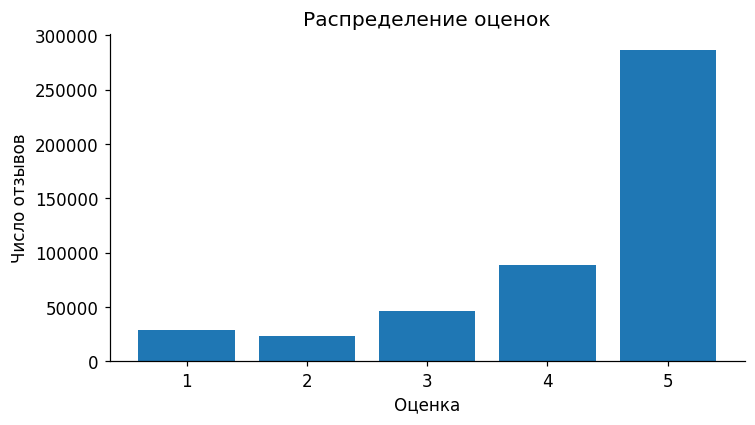

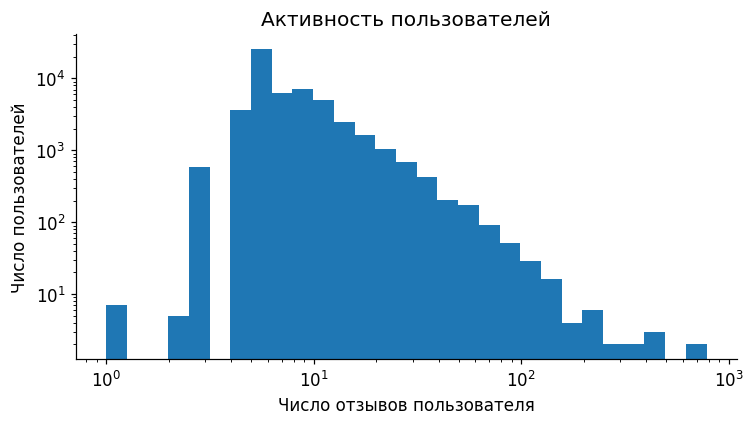

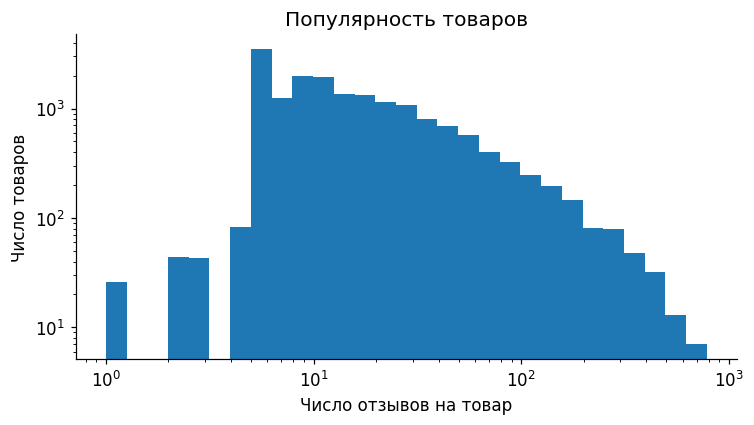

,user_activity,item_popularity
count,55223.000000,17408.000000
mean,8.573004,27.195944
std,10.095808,47.372128
min,1.000000,1.000000
25%,5.000000,7.000000
50%,6.000000,12.000000
75%,9.000000,27.000000
max,779.000000,782.000000


Доля оценок 4–5: 79.21%


In [34]:
ratings = clean.rating.value_counts().sort_index()

plt.figure(figsize=(7, 4))
plt.bar(ratings.index, ratings.values)
plt.title("Распределение оценок")
plt.xlabel("Оценка")
plt.ylabel("Число отзывов")
plt.xticks([1, 2, 3, 4, 5])
plt.tight_layout()
plt.show()
activity = clean.groupby("user_id").size()

plt.figure(figsize=(7, 4))
plt.hist(activity, bins=np.geomspace(1, activity.max() + 1, 30))
plt.xscale("log")
plt.yscale("log")
plt.title("Активность пользователей")
plt.xlabel("Число отзывов пользователя")
plt.ylabel("Число пользователей")
plt.tight_layout()
plt.show()
popularity = clean.groupby("item_id").size()

plt.figure(figsize=(7, 4))
plt.hist(popularity, bins=np.geomspace(1, popularity.max() + 1, 30))
plt.xscale("log")
plt.yscale("log")
plt.title("Популярность товаров")
plt.xlabel("Число отзывов на товар")
plt.ylabel("Число товаров")
plt.tight_layout()
plt.show()
display(pd.DataFrame({'user_activity': activity.describe(), 'item_popularity': popularity.describe()}))
print(f'Доля оценок 4–5: {(clean.rating >= 4).mean():.2%}')

Активность пользователей и популярность товаров распределены неравномерно: медианное число отзывов  6 и 12, а среднее 8,57 и 27,20 соответственно. Положительные оценки 4–5 составляют 79,21% отзывов, но отсутствие взаимодействия не означает отрицательного отношения к товару.

### 2.3. Время и покрытие метаданными
 Рассмотрим число отзывов по месяцам и заполненность метаданных.

 Для FM использую бренд и категории, заменяя пропуски на UNKNOWN без удаления взаимодействий. Путь категорий обрезаю на HTML-разделителе или описательном тексте (эвристика: знак конца предложения либо метка длиннее 80 символов), после чего оставляю до четырёх последних уровней.


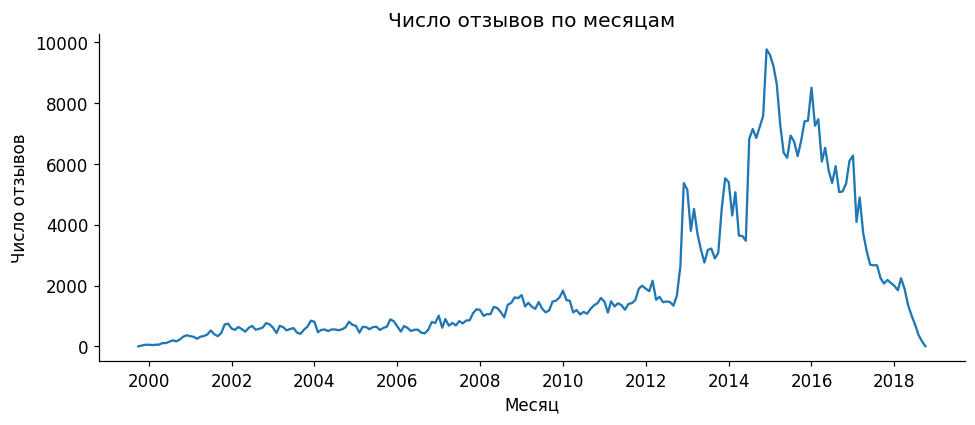

,Доля товаров
Название заполнено,0.998909
Бренд известен,0.992015
Категория известна,0.990177


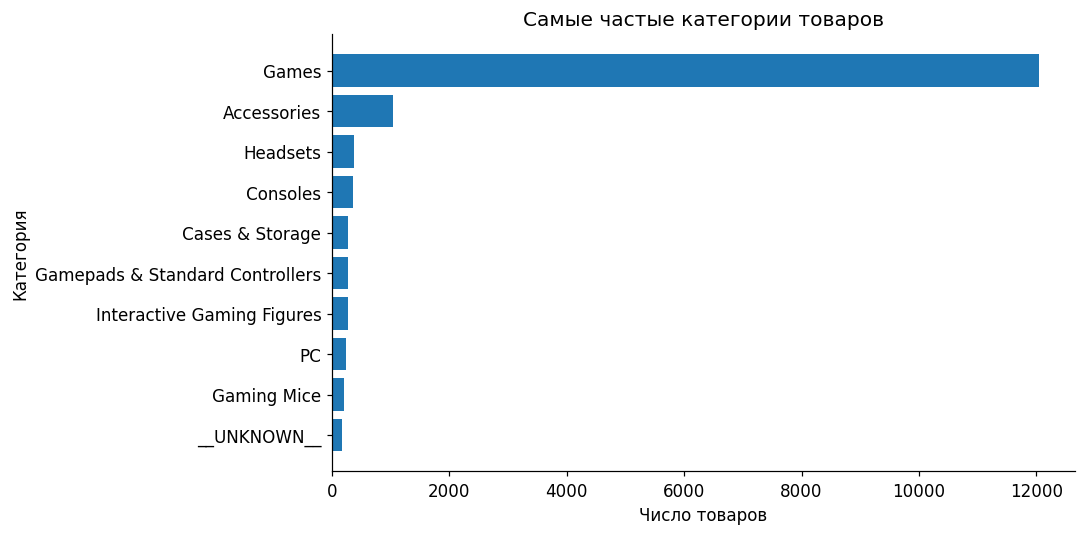

In [35]:
monthly = clean.set_index("date").resample("MS").size()
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(monthly.index, monthly.values)
ax.set(
    title="Число отзывов по месяцам",
    xlabel="Месяц",
    ylabel="Число отзывов"
)
plt.tight_layout()
plt.show()
eda_meta = align_metadata(metadata, sorted(clean.item_id.unique()))
metadata_coverage = pd.Series({
    "Название заполнено": eda_meta.title.ne("").mean(),
    "Бренд известен": eda_meta.brand.ne("__UNKNOWN__").mean(),
    "Категория известна": eda_meta.primary_category.ne("__UNKNOWN__").mean()
}, name="Доля товаров")
display(metadata_coverage.to_frame())
top_categories = (eda_meta.primary_category.value_counts().head(10).sort_values()
)
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top_categories.index, top_categories.values)
ax.set(
    title="Самые частые категории товаров",
    xlabel="Число товаров",
    ylabel="Категория"
)
plt.tight_layout()
plt.show()

Наибольшее число отзывов приходится на 2014–2016 годы, а среди категорий товаровпреобладает Games. Метаданные заполнены почти полностью.

## 3. Итоговая выборка

### 3.1. Временное разбиение и отбор
Разбиение примерно 80% / 10% / 10%.
Границы соответствуют временным квантилям очищенных взаимодействий; одинаковые timestamps всегда остаются в одном периоде.

По train выбираю до 4000 наиболее активных товаров и до 20000 наиболее активных пользователей. При равных частотах использую исходный ID. Потом удаляю пользователей и товары с менее чем пятью train-взаимодействиями.
Новые относительно train пользователи и товары исключаются из оценки.

In [38]:
def temporal_prepare(clean, max_items=4000, max_users=12000, min_user=5, min_item=5):
    timestamps = np.sort(clean.timestamp.to_numpy())
    train_end, valid_end = [int(np.quantile(timestamps, q, method="nearest")) for q in (0.8, 0.9)]
    raw_train = clean[clean.timestamp <= train_end].copy()
    raw_valid = clean[(clean.timestamp > train_end) & (clean.timestamp <= valid_end)].copy()
    raw_test = clean[clean.timestamp > valid_end].copy()

    def frequent_ids(frame, column, limit):
        counts = frame.groupby(column).size().rename("count").reset_index()
        return counts.sort_values(["count", column], ascending=[False, True]).head(limit)[column]

    catalog = frequent_ids(raw_train, "item_id", max_items)
    selected = raw_train[raw_train.item_id.isin(catalog)].copy()
    users = frequent_ids(selected, "user_id", max_users)
    selected = selected[selected.user_id.isin(users)].copy()
    while True:
        before = len(selected)
        uc = selected.groupby("user_id").size()
        ic = selected.groupby("item_id").size()
        selected = selected[selected.user_id.isin(uc[uc >= min_user].index) & selected.item_id.isin(ic[ic >= min_item].index)]
        if len(selected) == before:
            break
    user_ids = sorted(selected.user_id.unique())
    item_ids = sorted(selected.item_id.unique())
    user_map, item_map = ({v: i for i, v in enumerate(ids)} for ids in [user_ids, item_ids])

    def mapped(frame):
        out = frame[frame.user_id.isin(user_map) & frame.item_id.isin(item_map)].copy()
        out["u"] = out.user_id.map(user_map).astype("int64")
        out["i"] = out.item_id.map(item_map).astype("int64")
        return out.reset_index(drop=True)

    train, valid, test = mapped(selected), mapped(raw_valid), mapped(raw_test)
    rows = []
    for name, source, retained in [("train", raw_train, train), ("validation", raw_valid, valid),
                                    ("test", raw_test, test)]:
        rows.append({"split": name, "before": len(source), "retained": len(retained),
                     "new_to_raw_train_user": int((~source.user_id.isin(raw_train.user_id)).sum()),
                     "new_to_raw_train_item": int((~source.item_id.isin(raw_train.item_id)).sum()),
                     "outside_selected_users": int((~source.user_id.isin(user_map)).sum()),
                     "outside_selected_items": int((~source.item_id.isin(item_map)).sum())})
    total = sum(map(len, [train, valid, test]))
    assert train.timestamp.max() < raw_valid.timestamp.min()
    assert raw_valid.timestamp.max() < raw_test.timestamp.min()
    return {"train": train, "valid": valid, "test": test, "user_ids": user_ids,
            "item_ids": item_ids, "shape": (len(user_ids), len(item_ids)),
            "split_audit": pd.DataFrame(rows), "train_end": train_end, "valid_end": valid_end}


def build_item_features(metadata, include_metadata=True):
    n = len(metadata)
    if not include_metadata:
        return sparse.eye(n, format="csr"), {"item_ids": n, "brands": 0, "categories": 0}
    brands = {x: k for k, x in enumerate(sorted(metadata.brand.unique()))}
    cats = {x: k for k, x in enumerate(sorted({c for cs in metadata.categories for c in cs}))}
    rows, cols, values = list(range(n)), list(range(n)), [1.0] * n
    for i, row in metadata.iterrows():
        rows.append(i)
        cols.append(n + brands[row.brand])
        values.append(1.0)
        unique = sorted(set(row.categories))
        for category in unique:
            rows.append(i)
            cols.append(n + len(brands) + cats[category])
            values.append(1.0 / np.sqrt(len(unique)))
    matrix = sparse.csr_matrix((values, (rows, cols)), shape=(n, n + len(brands) + len(cats)))
    return matrix, {"item_ids": n, "brands": len(brands), "categories": len(cats)}

def interaction_matrix(frame, shape, positive_only=False):
    subset = frame[frame.rating >= 4] if positive_only else frame
    result = sparse.csr_matrix((np.ones(len(subset)), (subset.u, subset.i)), shape=shape)
    result.data[:] = 1.0
    return result

In [41]:
prepare_config = {k: v for k, v in CONFIG.items() if k != 'max_eval_users'}
prepared = temporal_prepare(clean, **prepare_config)
train, valid, test = [prepared[key] for key in ['train', 'valid', 'test']]
shape = prepared['shape']
items = align_metadata(metadata, prepared['item_ids'])
meta_features, feature_counts = build_item_features(items, include_metadata=True)
id_features, _ = build_item_features(items, include_metadata=False)
categories = items.primary_category.to_numpy()
display(prepared['split_audit'])
data_summary = pd.DataFrame([
    {'stage': 'До очистки', 'interactions': len(raw), 'users': raw.user_id.nunique(), 'items': raw.item_id.nunique()},
    {'stage': 'После очистки', 'interactions': len(clean), 'users': clean.user_id.nunique(), 'items': clean.item_id.nunique()},
    {'stage': 'Итоговая выборка', 'interactions': sum(map(len, [train, valid, test])), 'users': shape[0], 'items': shape[1]},
])
display(data_summary)
density = len(train) / (shape[0] * shape[1])
print(f'Train разреженность={1 - density:.6%}')
print('Границы train/validation:', pd.to_datetime(prepared['train_end'], unit='s', utc=True))
print('Границы validation/test:', pd.to_datetime(prepared['valid_end'], unit='s', utc=True))
print('Признаки объектов:', feature_counts)


,split,before,retained,new_to_raw_train_user,new_to_raw_train_item,outside_selected_users,outside_selected_items
0,train,378850,178183,0,0,144083,116550
1,validation,47385,3861,16294,9706,37367,24487
2,test,47192,2768,20030,11475,39396,26723


,stage,interactions,users,items
0,До очистки,497577,55223,17408
1,После очистки,473427,55223,17408
2,Итоговая выборка,184812,20000,4000


Train разреженность=99.777271%
Границы train/validation: 2016-05-05 00:00:00+00:00
Границы validation/test: 2017-01-15 00:00:00+00:00
Признаки объектов: {'item_ids': 4000, 'brands': 416, 'categories': 79}


После отбора по train итоговая выборка содержит 184 812 взаимодействий, 20 000 пользователей и 4000 товаров. Разреженность train составляет 99,78%, а сокращение validation и test связано с исключением взаимодействий пользователей и товаров, не вошедших в выбранные по train наборы.

### 3.2. Оценка

Случайно выбираем 2000 пользователей из train,
при validation исключаем все train-товары пользователя; при test — все известные
товары из train+validation. Отсутствие отзыва считаю неизвестным
отношением. На test релевантность всегда определяется будущей оценкой не ниже 4.

### 3.3. Метрики K = 10

Первая етрика  NDCG@10: она учитывает, насколько высоко в списке стоят
релевантные товары. Вторая **Recall@10**: доля релевантных будущих товаров,
которые попали в десятку.

$$DCG_u@10=\sum_{r=1}^{10}\frac{\mathbb{1}[i_r\in R_u]}{\log_2(r+1)}\qquad
NDCG_u@10=\frac{DCG_u@10}{\sum_{r=1}^{\min(10,|R_u|)}1/\log_2(r+1)}$$

$$Recall_u@10=\frac{|Top10_u\cap R_u|}{|R_u|}$$
еще Precision@10, HitRate@10 и покрытие

In [42]:
def training_cohort(n_users, max_users=2000, seed=42):
    return np.sort(np.random.default_rng(seed).choice(
        n_users, size=min(max_users, n_users), replace=False))
def ground_truth(future, seen, cohort, k=10):
    allowed = set(map(int, cohort))
    truth = {}
    for user, group in future[future.rating >= 4].groupby("u"):
        user = int(user)
        if user not in allowed:
            continue
        known = set(seen.getrow(user).indices)
        relevant = set(map(int, group.i)) - known
        if relevant:
            truth[user] = relevant
    candidate_counts = seen.shape[1] - np.diff(seen.indptr)
    users = np.array(sorted(u for u in truth if candidate_counts[u] >= k), dtype=int)
    truth = {int(u): truth[int(u)] for u in users}
    return users, truth
def user_metrics(recommended, relevant, k=10):
    recommended = np.asarray(recommended)[:k]
    hits = np.array([int(i) in relevant if i >= 0 else False for i in recommended], dtype=float)
    discounts = 1.0 / np.log2(np.arange(2, k + 2))
    ideal = discounts[:min(k, len(relevant))].sum()
    return {"NDCG@10": float((hits * discounts[:len(hits)]).sum() / ideal),
            "Recall@10": float(hits.sum() / len(relevant)),
            "Precision@10": float(hits.sum() / k), "HitRate@10": float(hits.any())}

In [43]:
def evaluate(model, users, truth, seen, k=10, batch_size=128):
    rows, distinct = [], set()
    for start in range(0, len(users), batch_size):
        batch = users[start:start + batch_size]
        recommendations = model.recommend(batch, seen, k)
        for user, recommended in zip(batch, recommendations):
            history = set(seen.getrow(int(user)).indices)
            valid = recommended[recommended >= 0]
            assert len(valid) == k and len(set(valid)) == k and not (set(valid) & history)
            distinct.update(map(int, valid))
            rows.append({"u": int(user), **user_metrics(recommended, truth[int(user)], k)})
    per_user = pd.DataFrame(rows).set_index("u")
    metrics = per_user.mean().to_dict()
    metrics["CatalogCoverage@10"] = len(distinct) / seen.shape[1]
    metrics["n_evaluated_users"] = len(per_user)
    return metrics, per_user

def paired_bootstrap(first, second, metric="NDCG@10", seed=42, repetitions=1000):
    aligned = first[[metric]].join(second[[metric]], lsuffix="_a", rsuffix="_b", how="inner")
    delta = aligned.iloc[:, 0].to_numpy() - aligned.iloc[:, 1].to_numpy()
    rng = np.random.default_rng(seed)
    means = np.array([rng.choice(delta, len(delta), replace=True).mean() for _ in range(repetitions)])
    low, high = np.quantile(means, [0.025, 0.975])
    return {"mean_delta": float(delta.mean()), "ci95_low": float(low), "ci95_high": float(high),
            "users": len(delta), "bootstrap_repetitions": repetitions}

In [44]:
seen_train = interaction_matrix(train, shape)

cohort = training_cohort(
    shape[0], CONFIG["max_eval_users"], SEED
)

valid_users, valid_truth = ground_truth(
    valid, seen_train, cohort, K
)

## 4. Модели

### 4.1. ItemKNN

Я выбрала item-based коллаборативную фильтрацию: сходство товаров определяю по общим положительным взаимодействиям.

 $X_{ui}=1$, если в истории есть оценка не ниже 4, иначе $0$.
Косинусное сходство уменьшаем при малом числе общих пользователей:

$$s_{ij}=\frac{X_i^\top X_j}{\|X_i\|\|X_j\|}
\frac{n_{ij}}{n_{ij}+h},\qquad s_{ii}=0.$$

Для каждого целевого товара $j$ оставляю $k$ лучших соседей. Оценка:
$\hat y_{uj}=\sum_{i\in I_u^+}X_{ui}s_{ij}$. Для товара без позитивов сходства нулевые.
Я использую невзвешенную сумму: товарные векторы уже нормированы при cosine.

### 4.2.  ALS


Оценки переводим в  в $t_{ui}=(r_{ui}-3)/2$.

Пропущенные отзывы не входят в функцию потерь:

$$\min_{P,Q}\sum_{(u,i)\in\Omega}(t_{ui}-p_u^\top q_i)^2
 +\lambda(\|P\|_F^2+\|Q\|_F^2).$$

Попеременное обновление:
$p_u=(Q_{I_u}^\top Q_{I_u}+\lambda I)^{-1}Q_{I_u}^\top t_u$,
аналогично для $q_i$. Решается линейная система не вычисляя обратную матрицу явно.

### 4.3. EASE


Я использую тот же положительный $X$, что у ItemKNN:

$$\min_B\|X-XB\|_F^2+\lambda\|B\|_F^2,\quad diag(B)=0.$$

При $P=(X^\top X+\lambda I)^{-1}$ имеем
$B_{ij}=-P_{ij}/P_{jj}$ для $i\ne j$ и $B_{jj}=0$

### 4.4. FM с метапризнаками

Я использую FM второго порядка с метапризнаками бренда и категорий товара.

Вектор $x_{ui}$ содержит one-hot пользователя, one-hot товара, one-hot бренда
и multi-hot категорий товара. Категории нормированы на $1/\sqrt{m_i}$, чтобы товары
с большим числом категорий не получали автоматически больший масштаб.
Бренд и категории описывают ассортимент и дают обмен информацией между товарами.
Неизвестные значения имеют отдельный токен.

$$\hat t(x)=w_0+\sum_j w_jx_j+
\frac12\sum_f\left[(\sum_jv_{jf}x_j)^2-\sum_jv_{jf}^2x_j^2\right].$$

Обучаем по наблюдаемым оценкам: $\frac{1}{2N}\sum(\hat t-t)^2+
\frac\lambda2(\|w\|^2+\|V\|_F^2)$, где $t=(r-3)/2$.
Пропущенные взаимодействия не превращаются в отрицательные примеры.
Для ранжирования FM разлагается на предвычисленный вклад товара и скалярное
произведение пользовательского эмбеддинга с суммой эмбеддингов признаков товара.

Признаки: категории и бренд считаются статическими и доступными заранее.

 Цена, sales rank, число отзывов,
средний рейтинг товара, полезность и текст отзыва исключены: они могут
содержать информацию из будущего.  FM IDs only измеряет вклад метаданных.

### 4.5. ALS с собственным целевым сигналом

Oценкa отклонением от привычной оценки пользователя и его предпочтением категории. Все статистики рассчитываю только по обучающим данным: train при подборе настроек и train+validation при финальном обучении.


- $r_{ui}$ оценка пользователя $u$ товару $i$.
- $I_u$ товары, оценённые пользователем в обучающей истории; $I_u|$ — их количество.
- $\mu$ средняя оценка по всем обучающим взаимодействиям.
- $\mu_u$ сглаженная средняя оценка пользователя.
- $c(i)$ основная категория товара $i$.
- $q_c$ доля оценок 4–5 в категории $c$ среди всех пользователей.
- $n_{uc}$ количество оценок пользователя $u$ в категории $c$, а $n^+_{uc}$ количество среди них оценок 4–5.
- $q_{uc}$ сглаженная доля положительных оценок пользователя в категории.
- $s=5$ коэффициент сглаживания, уменьшающий влияние статистик, рассчитанных по малому числу оценок.

Сглаженные статистики:

$$
\mu_u=\frac{\sum_{i\in I_u}r_{ui}+s\mu}{|I_u|+s},
\qquad
q_{uc}=\frac{n^+_{uc}+s q_c}{n_{uc}+s}.
$$

Целевой сигнал:

$$
t^{custom}_{ui}
=
\frac{r_{ui}-3}{2}
+
\beta\frac{r_{ui}-\mu_u}{2}
+
\gamma\left(q_{u,c(i)}-q_{c(i)}\right)
$$

Первый член - нормированная оценка, второй - отклонение от привычной оценки пользователя, третий — отклонение его доли положительных оценок категории от общей доли. Коэффициенты $\beta$ и $\gamma$ определяют вклад двух добавок и подбираются по validation.

Остальные настройки и алгоритм обучения совпадают с базовым ALS: изменяется именно таргет, а веса наблюдений остаются равными 1.

## 5. Подбор гиперпараметров на validation
 Настройки выбираю по максимуму
validation NDCG@10.
Для FM с метаданными и FM только с ID использую одинаковое пространство поиска.
Для Custom ALS сохраняю размерность, регуляризацию и число итераций лучшего
базового ALS и подбираю коэффициенты нового таргета.

In [45]:
def fit_model(name, params, train, shape, meta_features, id_features, categories, seed=42):
    if name == "ItemKNN":
        model = ItemKNN(**params).fit(interaction_matrix(train, shape, positive_only=True))
    elif name == "EASE":
        model = EASE(**params).fit(interaction_matrix(train, shape, positive_only=True))
    elif name == "ALS":
        model = ExplicitALS(seed=seed, **params).fit(target_matrix(train, shape))
    elif name == "Custom ALS":
        model = CustomTargetALS(seed=seed, **params).fit(train, shape, categories)
    elif name in {"FM + metadata", "FM IDs only"}:
        features = meta_features if name == "FM + metadata" else id_features
        model = FactorizationMachine(seed=seed, **params).fit(train, features, shape[0])
    return model


def validation_search(name, grid, train, shape, meta_features, id_features, categories,
                      users, truth, seen, seed=42):
    records, best, best_value = [], None, -np.inf
    for number, params in enumerate(grid):
        started = time.perf_counter()
        model = fit_model(name, params, train, shape, meta_features, id_features, categories, seed)
        fit_seconds = time.perf_counter() - started
        metrics, _ = evaluate(model, users, truth, seen)
        losses = getattr(model, "loss_history", [])
        records.append({"model": name, "trial": number, "parameters": json.dumps(params, sort_keys=True),
                        "fit_seconds": fit_seconds,
                        "train_loss_start": losses[0] if losses else np.nan,
                        "train_loss_end": losses[-1] if losses else np.nan,
                        **metrics})
        print(f"{name}: {number + 1}/{len(grid)}, validation NDCG@10={metrics['NDCG@10']:.5f}", flush=True)
        if metrics["NDCG@10"] > best_value:
            best_value, best = metrics["NDCG@10"], dict(params)
        del model
        gc.collect()
    return best, pd.DataFrame(records)

In [48]:
GRIDS = {
    'ItemKNN': [dict(k=50, shrink=10), dict(k=100, shrink=25)],
    'ALS': [dict(factors=16, reg=1.0, iterations=12),
            dict(factors=32, reg=5.0, iterations=12)],
    'EASE': [dict(reg=100.0), dict(reg=500.0)],
    'FM + metadata': [dict(factors=16, reg=0.00001, learning_rate=0.01, epochs=12, batch_size=4096),
                       dict(factors=32, reg=0.0001, learning_rate=0.01, epochs=12, batch_size=4096)],
}
GRIDS['FM IDs only'] = [dict(p) for p in GRIDS['FM + metadata']]
TARGET_GRID = [dict(beta=0.25, gamma=0.25), dict(beta=0.5, gamma=0.5),
               dict(beta=0.5, gamma=1.0)]
display(pd.DataFrame([{'model': name, 'grid': json.dumps(grid)} for name, grid in GRIDS.items()]))

,model,grid
0,ItemKNN,"[{""k"": 50, ""shrink"": 10}, {""k"": 100, ""shrink"":..."
1,ALS,"[{""factors"": 16, ""reg"": 1.0, ""iterations"": 12}..."
2,EASE,"[{""reg"": 100.0}, {""reg"": 500.0}]"
3,FM + metadata,"[{""factors"": 16, ""reg"": 1e-05, ""learning_rate""..."
4,FM IDs only,"[{""factors"": 16, ""reg"": 1e-05, ""learning_rate""..."


In [49]:
best_parameters, validation_frames = {}, []
search_order = ['ItemKNN', 'ALS', 'EASE', 'FM + metadata', 'FM IDs only', 'Custom ALS']
for name in search_order:
    grid = GRIDS[name] if name != 'Custom ALS' else [
        dict(**best_parameters['ALS'], **target, smoothing=5.0) for target in TARGET_GRID]
    best, trials = validation_search(name, grid, train, shape, meta_features, id_features,
                                     categories, valid_users, valid_truth, seen_train, SEED)
    best_parameters[name] = best
    validation_frames.append(trials)
validation_results = pd.concat(validation_frames, ignore_index=True)
display(validation_results[['model', 'parameters', PRIMARY_METRIC, 'Recall@10', 'fit_seconds']].round(5))
display(validation_results[validation_results.model.str.startswith('FM')][
    ['model', 'trial', 'train_loss_start', 'train_loss_end', PRIMARY_METRIC]])


ItemKNN: 1/2, validation NDCG@10=0.05307
ItemKNN: 2/2, validation NDCG@10=0.05253
ALS: 1/2, validation NDCG@10=0.00823
ALS: 2/2, validation NDCG@10=0.01143
EASE: 1/2, validation NDCG@10=0.05746
EASE: 2/2, validation NDCG@10=0.04700
FM + metadata: 1/2, validation NDCG@10=0.00000
FM + metadata: 2/2, validation NDCG@10=0.00155
FM IDs only: 1/2, validation NDCG@10=0.00692
FM IDs only: 2/2, validation NDCG@10=0.00232
Custom ALS: 1/3, validation NDCG@10=0.00951
Custom ALS: 2/3, validation NDCG@10=0.01044
Custom ALS: 3/3, validation NDCG@10=0.01231


,model,parameters,NDCG@10,Recall@10,fit_seconds
0,ItemKNN,"{""k"": 50, ""shrink"": 10}",0.05307,0.09304,1.38618
1,ItemKNN,"{""k"": 100, ""shrink"": 25}",0.05253,0.08919,1.22198
2,ALS,"{""factors"": 16, ""iterations"": 12, ""reg"": 1.0}",0.00823,0.01392,8.27079
3,ALS,"{""factors"": 32, ""iterations"": 12, ""reg"": 5.0}",0.01143,0.01667,13.06129
4,EASE,"{""reg"": 100.0}",0.05746,0.10183,5.80038
5,EASE,"{""reg"": 500.0}",0.04700,0.08452,4.95407
6,FM + metadata,"{""batch_size"": 4096, ""epochs"": 12, ""factors"": ...",0.00000,0.00000,8.82320
7,FM + metadata,"{""batch_size"": 4096, ""epochs"": 12, ""factors"": ...",0.00155,0.00256,17.68220
8,FM IDs only,"{""batch_size"": 4096, ""epochs"": 12, ""factors"": ...",0.00692,0.01026,7.90009
9,FM IDs only,"{""batch_size"": 4096, ""epochs"": 12, ""factors"": ...",0.00232,0.00769,15.84879


,model,trial,train_loss_start,train_loss_end,NDCG@10
6,FM + metadata,0,0.165474,0.065776,0.000000
7,FM + metadata,1,0.180591,0.136406,0.001555
8,FM IDs only,0,0.209846,0.076607,0.006923
9,FM IDs only,1,0.218684,0.132511,0.002316


## 6. Финальное сравнение при K = 10

После выбора настроек переобучаем на train+validation. Для Custom ALS статистики таргета пересчитываем на этой обучающей истории.
Test используем только для окончательной оценки.
Для всех моделей фиксируем одинаковых test-пользователей, кандидатов и исключения.

In [50]:
train_valid = pd.concat([train, valid], ignore_index=True)
seen_final = interaction_matrix(train_valid, shape)
test_users, test_truth = ground_truth(test, seen_final, cohort, K)

final_records, individual_results, examples = [], {}, []

final_specs = [(name, best_parameters[name]) for name in search_order]
if best_parameters["FM IDs only"] != best_parameters["FM + metadata"]:
    final_specs.append(("FM IDs matched", best_parameters["FM + metadata"]))

chosen_user = int(test_users[0])

for name, parameters in final_specs:
    factory_name = "FM IDs only" if name == "FM IDs matched" else name

    started = time.perf_counter()
    model = fit_model(
        factory_name, parameters, train_valid, shape,
        meta_features, id_features, categories, SEED
    )
    fit_seconds = time.perf_counter() - started

    metrics, per_user = evaluate(
        model, test_users, test_truth, seen_final, K
    )

    final_records.append({
        "model": name,
        "parameters": json.dumps(parameters, sort_keys=True),
        "fit_seconds": fit_seconds,
        **metrics
    })
    individual_results[name] = per_user

    recs = model.recommend([chosen_user], seen_final, K)[0]
    for rank, item in enumerate(recs, 1):
        if item >= 0:
            examples.append({
                "model": name,
                "u": chosen_user,
                "rank": rank,
                "item_id": prepared["item_ids"][item],
                "title": items.iloc[item].title,
                "category": categories[item],
                "relevant_in_test": int(item in test_truth[chosen_user])
            })

    print(f"{name}: test NDCG@10={metrics['NDCG@10']:.5f}")
    del model
    gc.collect()

test_results = pd.DataFrame(final_records).set_index("model")
main_results = test_results.loc[MAIN_MODELS].sort_values(
    PRIMARY_METRIC, ascending=False
)

display(main_results[[
    PRIMARY_METRIC, "Recall@10", "Precision@10", "HitRate@10",
    "CatalogCoverage@10", "fit_seconds", "parameters"
]].round(5))

ItemKNN: test NDCG@10=0.01695
ALS: test NDCG@10=0.01507
EASE: test NDCG@10=0.02112
FM + metadata: test NDCG@10=0.00000
FM IDs only: test NDCG@10=0.00000
Custom ALS: test NDCG@10=0.01390
FM IDs matched: test NDCG@10=0.00269


,NDCG@10,Recall@10,Precision@10,HitRate@10,CatalogCoverage@10,fit_seconds,parameters
model,,,,,,,
EASE,0.02112,0.04189,0.00887,0.08065,0.13625,5.04254,"{""reg"": 100.0}"
ItemKNN,0.01695,0.03282,0.00645,0.06452,0.15025,1.12482,"{""k"": 50, ""shrink"": 10}"
ALS,0.01507,0.02688,0.00323,0.03226,0.03950,13.26076,"{""factors"": 32, ""iterations"": 12, ""reg"": 5.0}"
Custom ALS,0.01390,0.03629,0.00565,0.05645,0.06925,13.60725,"{""beta"": 0.5, ""factors"": 32, ""gamma"": 1.0, ""it..."
FM + metadata,0.00000,0.00000,0.00000,0.00000,0.01475,18.79032,"{""batch_size"": 4096, ""epochs"": 12, ""factors"": ..."


### 6.1. Итоги

Сравнимаем пять основных моделей по NDCG@10 и Recall@10; дополнительные метрики
характеризуют точность выдачи, наличие хотя бы одного попадания и разнообразие каталога.

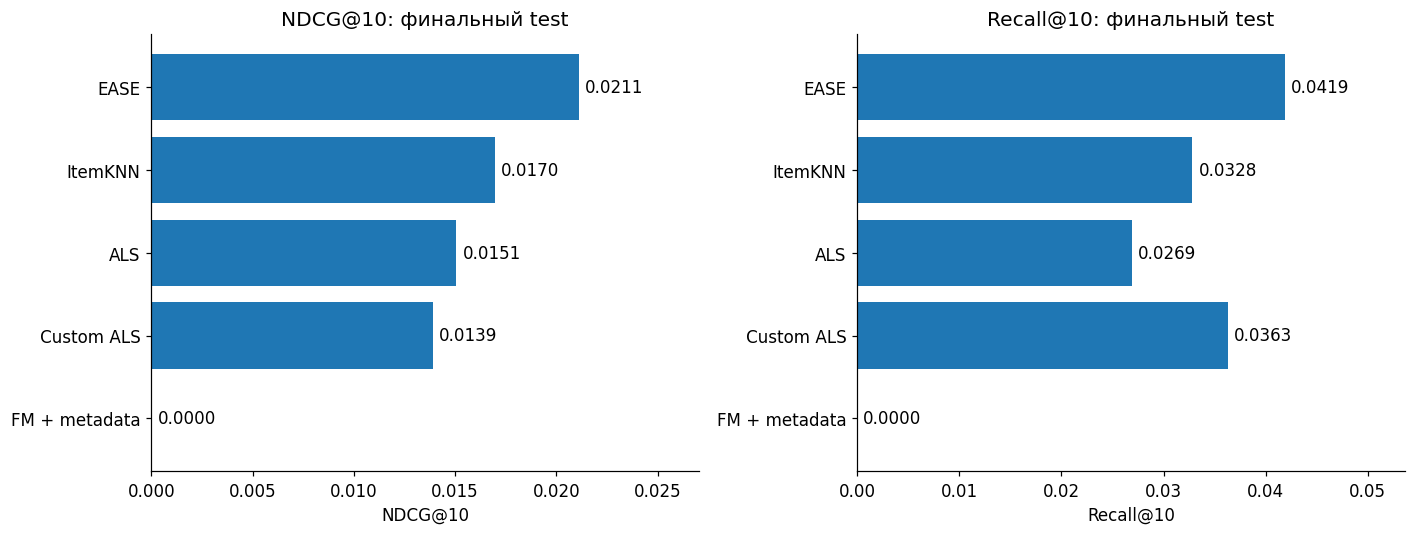

,model,k,shrink,factors,reg,iterations,learning_rate,epochs,batch_size,beta,gamma,smoothing
0,ItemKNN,50.0,10.0,—,—,—,—,—,—,—,—,—
1,ALS,—,—,32.0,5.0,12.0,—,—,—,—,—,—
2,EASE,—,—,—,100.0,—,—,—,—,—,—,—
3,FM + metadata,—,—,32.0,0.0001,—,0.01,12.0,4096.0,—,—,—
4,FM IDs only,—,—,16.0,0.00001,—,0.01,12.0,4096.0,—,—,—
5,Custom ALS,—,—,32.0,5.0,12.0,—,—,—,0.5,1.0,5.0


In [51]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ordered = main_results.sort_values(PRIMARY_METRIC)

for ax, metric in zip(axes, [PRIMARY_METRIC, "Recall@10"]):
    bars = ax.barh(ordered.index, ordered[metric])
    ax.set(
        title=metric + ": финальный test",
        xlabel=metric,
        xlim=(0, max(0.01, ordered[metric].max() * 1.28))
    )
    ax.bar_label(bars, fmt="%.4f", padding=4)

plt.tight_layout()
plt.show()

display(pd.DataFrame([
    {"model": name, **params}
    for name, params in best_parameters.items()
]).fillna("—"))

### 6.2. Влияние метаданных и разработанного целевого сигнала

Сопоставим Custom ALS с базовым ALS и FM с метаданными с FM только на ID.
Дополнительно сравниваю FM при одинаковых гиперпараметрах, выбранных для основной FM,
чтобы отделить влияние признаков от выбора настроек.
Для средней разницы NDCG@10 строю 95% парный percentile-bootstrap-интервал
по одинаковым test-пользователям (1000 повторов, seed=42).
Этот интервал не учитывает вариацию от инициализации или временного разбиения.

In [52]:
matched_name = 'FM IDs matched' if 'FM IDs matched' in individual_results else 'FM IDs only'
pairs = [('Custom ALS', 'ALS'), ('FM + metadata', 'FM IDs only'), ('FM + metadata', matched_name)]
interval_rows = []
for first, second in dict.fromkeys(pairs):
    interval_rows.append({'first': first, 'second': second,
        **paired_bootstrap(individual_results[first], individual_results[second],
                           seed=SEED, repetitions=1000)})
comparison_intervals = pd.DataFrame(interval_rows)
display(comparison_intervals.round(6))
display(test_results.loc[['FM + metadata', 'FM IDs only', 'Custom ALS', 'ALS'],
                         [PRIMARY_METRIC, 'Recall@10', 'CatalogCoverage@10']].round(5))

,first,second,mean_delta,ci95_low,ci95_high,users,bootstrap_repetitions
0,Custom ALS,ALS,-0.001171,-0.017248,0.012127,124,1000
1,FM + metadata,FM IDs only,0.000000,0.000000,0.000000,124,1000
2,FM + metadata,FM IDs matched,-0.002688,-0.008065,0.000000,124,1000


,NDCG@10,Recall@10,CatalogCoverage@10
model,,,
FM + metadata,0.00000,0.00000,0.01475
FM IDs only,0.00000,0.00000,0.08475
Custom ALS,0.01390,0.03629,0.06925
ALS,0.01507,0.02688,0.03950


### 6.3. Пример рекомендаций

In [53]:
example_table = pd.DataFrame(examples)
display(example_table[example_table.model.isin(['ALS', 'Custom ALS'])].reset_index(drop=True))

,model,u,rank,item_id,title,category,relevant_in_test
0,ALS,273,1,B000B9RI14,Xbox 360 LIVE 1600 Points,Points & Currency Cards,0
1,ALS,273,2,B001SH7YMG,Red Dead Redemption,Games,0
2,ALS,273,3,B003ZSP0WW,Xbox 360 Wireless Controller - Glossy Black,Gamepads & Standard Controllers,0
3,ALS,273,4,B002AB7TX8,Demon's Souls,Games,0
4,ALS,273,5,B001JKTC9A,Uncharted 2: Among Thieves - Playstation 3,Games,0
5,ALS,273,6,B00GZ1GUSY,Tomb Raider: Definitive Edition - PlayStation 4,Games,0
6,ALS,273,7,B00JK00S0S,The Last of Us Remastered - PlayStation 4,Games,0
7,ALS,273,8,B000OLXX86,Mass Effect - Xbox 360,Games,0
8,ALS,273,9,B000FQ2D5E,Metal Gear Solid 4: Guns of the Patriots,Games,0
9,ALS,273,10,B002I0H79C,Gears of War 3,Consoles,0


## 7. Выводы и ограничения

Лучший результат на test показала **EASE** с параметром reg=100, выбранным по validation: NDCG@10 = 0,02112, Recall@10 = 0,04189. В этом эксперименте эта модель оказалась наиболее подходящей для формирования top-10 рекомендаций.

Разработанный целевой сигнал не улучшил основную метрику ALS: NDCG@10 снизилась с 0,01507 до 0,01390, хотя Recall@10 выросла.  Custom ALS находила большую долю релевантных товаров, но это не обеспечило улучшения с учётом их позиций в рекомендациях.

Оба варианта FM с отдельно подобранными настройками получили нулевые метрики на test: релевантные товары не попали в первые десять рекомендаций. При одинаковых настройках вариант без метаданных показал ненулевой результат, мы не получили что  считать метаданные полезно в этой постановке.

Итоговая выборка содержит 184812 взаимодействий, 20000 пользователей и 4000 товаров, но итоговое качество оценивалось только на 124 пользователях. Это ограничивает устойчивость результатов. И я использовала небольшие сетки гиперпараметров, одно случайное зерно и одно временное разбиение, новые пользователи и товары были исключены, а метаданные считались неизменными во времени. Поэтому полученные выводы относятся к выбранной подвыборке и методу оценки.